In [1]:
!pip install -q imatpy cobra pandas numpy matplotlib

In [2]:
import cobra
import pandas as pd
import numpy as np
import imatpy
import optlang

print("COBRApy:", cobra.__version__)
print("iMATpy:", imatpy.__version__)
print("Optlang:", optlang.__version__)

print("\nAvailable solvers:")
print(optlang.available_solvers)

COBRApy: 0.32.1
iMATpy: 0.3.0
Optlang: 1.9.1

Available solvers:
{'GUROBI': False, 'GLPK': True, 'MOSEK': False, 'CPLEX': False, 'COINOR_CBC': False, 'SCIPY': True, 'OSQP': True, 'HIGHS': True}


In [3]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving Human-GEM.xml to Human-GEM.xml

Uploaded files:
Human-GEM.xml


In [4]:
from google.colab import files

uploaded = files.upload()

Saving liver_reaction_weights_15.csv to liver_reaction_weights_15.csv


In [5]:
from google.colab import files

uploaded = files.upload()

Saving GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz to GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz


In [6]:
import os

required_files = [
    "Human-GEM.xml",
    "liver_reaction_weights_15.csv",
    "GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz"
]

for filename in required_files:
    print(filename, "FOUND" if os.path.exists(filename) else "MISSING")

Human-GEM.xml FOUND
liver_reaction_weights_15.csv FOUND
GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz FOUND


In [7]:
import cobra
import pandas as pd
import numpy as np
import os

model = cobra.io.read_sbml_model("/content/Human-GEM.xml")

print("Human-GEM loaded successfully!")
print("Reactions:", len(model.reactions))
print("Metabolites:", len(model.metabolites))
print("Genes:", len(model.genes))

Human-GEM loaded successfully!
Reactions: 12971
Metabolites: 8455
Genes: 2887


In [8]:
weights_file = "/content/liver_reaction_weights_15.csv"

df = pd.read_csv(weights_file)

print("Columns:", df.columns.tolist())
print("Rows:", len(df))
print("\nFirst five rows:")
display(df.head())

reaction_ids = df.iloc[:, 0].astype(str)
reaction_values = pd.to_numeric(df.iloc[:, 1], errors="raise")

weights = dict(zip(reaction_ids, reaction_values))

model_ids = {reaction.id for reaction in model.reactions}

matched = set(weights.keys()) & model_ids
unmatched = set(weights.keys()) - model_ids

print("\nMatched reactions:", len(matched))
print("Unmatched reactions:", len(unmatched))
print("Weight categories:")
print(pd.Series(list(weights.values())).value_counts())

assert len(matched) == len(weights), "Reaction IDs do not all match!"
assert len(weights) == len(model.reactions), "Reaction count mismatch!"

Columns: ['Unnamed: 0', '0']
Rows: 12971

First five rows:


,Unnamed: 0,0
0,MAR03905,1
1,MAR03907,1
2,MAR04097,0
3,MAR04099,0
4,MAR04108,0



Matched reactions: 12971
Unmatched reactions: 0
Weight categories:
 0    9576
 1    3082
-1     313
Name: count, dtype: int64


In [9]:
from imatpy.imat import (
    add_imat_constraints,
    add_imat_objective_
)

# Configure GLPK
model.solver = "glpk"

# Prepare iMAT constraints
imat_model = add_imat_constraints(
    model,
    weights,
    epsilon=0.01,
    threshold=0.001
)

# Add the iMAT objective
add_imat_objective_(imat_model, weights)

print("iMAT model prepared successfully!")
print("Variables:", len(imat_model.variables))
print("Constraints:", len(imat_model.constraints))
print("Solver:", imat_model.solver.interface.__name__)

iMAT model prepared successfully!
Variables: 32419
Constraints: 15245
Solver: optlang.glpk_interface


In [10]:
imat_model.solver.configuration.timeout = 1800

print("Starting iMAT optimisation...")

solution = imat_model.optimize()

print("\n===== iMAT RESULTS =====")
print("Status:", solution.status)
print("Objective:", solution.objective_value)

Starting iMAT optimisation...

===== iMAT RESULTS =====
Status: time_limit
Objective: 0.0


/usr/local/lib/python3.13/dist-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'time_limit'.
  warn(f"Solver status is '{status}'.", UserWarning)


In [11]:
!pip install -q gurobipy

import gurobipy as gp

print("Gurobi version:", gp.gurobi.version())

Gurobi version: (13, 0, 3)


In [12]:
!pip install -q pyscipopt

import pyscipopt

print("PySCIPOpt version:", pyscipopt.__version__)

from pyscipopt import Model

scip = Model("iMAT_test")

print("SCIP version:", scip.version())

PySCIPOpt version: 6.3.0
SCIP version: 10.0


In [13]:
# Export the complete iMAT mathematical model
lp_file = "/content/liver_imat_15.lp"

with open(lp_file, "w") as f:
    f.write(str(imat_model.solver))

print("iMAT optimisation model exported!")
print("File:", lp_file)

iMAT optimisation model exported!
File: /content/liver_imat_15.lp


In [14]:
from pyscipopt import Model

scip_model = Model("Human_Liver_iMAT")

# Read the exported optimisation problem
scip_model.readProblem(lp_file)

print("Successfully loaded into SCIP!")
print("SCIP variables:", scip_model.getNVars())
print("SCIP constraints:", scip_model.getNConss())
print("Objective sense:", scip_model.getObjectiveSense())

Successfully loaded into SCIP!
SCIP variables: 32419
SCIP constraints: 15245
Objective sense: maximize


In [15]:
variables = scip_model.getVars()

binary_count = sum(
    1 for v in variables if v.vtype() == "BINARY"
)

integer_count = sum(
    1 for v in variables if v.vtype() == "INTEGER"
)

continuous_count = sum(
    1 for v in variables if v.vtype() == "CONTINUOUS"
)

print("Total variables:", len(variables))
print("Binary variables:", binary_count)
print("Integer variables:", integer_count)
print("Continuous variables:", continuous_count)

Total variables: 32419
Binary variables: 0
Integer variables: 6477
Continuous variables: 25942


In [16]:
integer_vars = [
    v for v in scip_model.getVars()
    if v.vtype() == "INTEGER"
]

binary_like = [
    v for v in integer_vars
    if abs(v.getLbGlobal()) < 1e-9
    and abs(v.getUbGlobal() - 1) < 1e-9
]

print("Integer variables:", len(integer_vars))
print("Integer variables with 0-1 bounds:", len(binary_like))
print("Other integer variables:", len(integer_vars) - len(binary_like))

Integer variables: 6477
Integer variables with 0-1 bounds: 6477
Other integer variables: 0


In [17]:
# Set maximum optimisation time: 30 minutes
scip_model.setParam("limits/time", 1800)

# Display optimisation progress
scip_model.setParam("display/verblevel", 4)

print("Starting iMAT optimisation using SCIP...")
print("Please wait.")

scip_model.optimize()

# Display results
print("\n===== iMAT OPTIMISATION RESULTS =====")

status = scip_model.getStatus()
number_solutions = scip_model.getNSols()

print("Status:", status)
print("Solutions found:", number_solutions)

if number_solutions > 0:
    best_solution = scip_model.getBestSol()

    print("Best objective:",
          scip_model.getSolObjVal(best_solution))

    print("Optimality gap:", scip_model.getGap())

else:
    print("No feasible solution was found.")

Starting iMAT optimisation using SCIP...
Please wait.

===== iMAT OPTIMISATION RESULTS =====
Status: timelimit
Solutions found: 100
Best objective: 3021.000000000001
Optimality gap: 0.0013240519696425398


In [18]:
best_solution = scip_model.getBestSol()

print("Best objective:", scip_model.getSolObjVal(best_solution))
print("Number of solutions:", scip_model.getNSols())

print("\nSample solution variables:")

for var in scip_model.getVars()[:10]:
    print(var.name, scip_model.getSolVal(best_solution, var))

Best objective: 3021.000000000001
Number of solutions: 100

Sample solution variables:
y_high_pos_MAR03905_537755cd 1.0
y_high_neg_MAR03905_5179ce6a 0.0
y_high_pos_MAR03907_7fe7fc74 1.0
y_high_neg_MAR03907_4a0700a0 0.0
y_high_pos_MAR04281_9fbc950e 0.0
y_high_neg_MAR04281_d7b1ca7d 1.0
y_high_pos_MAR04388_f9533797 0.0
y_high_neg_MAR04388_2caa15fb 1.0
y_high_pos_MAR08357_001fb118 1.0
y_high_neg_MAR08357_a9c305a7 0.0


In [20]:
# Get the best feasible solution
best_solution = scip_model.getBestSol()

# Identify continuous variables
continuous_vars = [
    v for v in scip_model.getVars()
    if v.vtype() == "CONTINUOUS"
]

print("Continuous variables:", len(continuous_vars))

print("\nFirst 30 continuous variables and values:")

for var in continuous_vars[:30]:
    print(
        var.name,
        "=",
        scip_model.getSolVal(best_solution, var)
    )

Continuous variables: 25942

First 30 continuous variables and values:
MAR08596 = 0.01
MAR08596_reverse_216f7 = 0.0
MAR08597 = 0.01
MAR08597_reverse_bcc55 = 0.0
MAR09277 = 0.01
MAR09277_reverse_23abc = 0.0
MAR08601 = 0.01
MAR08601_reverse_fdab7 = 0.0
MAR08600 = 0.0
MAR08600_reverse_e30ab = 0.01
MAR09267 = 0.0
MAR09267_reverse_07c27 = 0.01
MAR00241 = 0.05938760989037467
MAR00241_reverse_9abae = 0.0
MAR00242 = 0.01
MAR00242_reverse_4d23f = 0.0
MAR00685 = 0.0
MAR00685_reverse_9e3b0 = 0.0
MAR00686 = 0.0
MAR00686_reverse_26888 = 0.0
MAR00687 = 0.0
MAR00687_reverse_69875 = 0.0
MAR00688 = 0.0
MAR00688_reverse_bd90d = 0.0
MAR00689 = 0.0
MAR00689_reverse_fd4d2 = 0.0
MAR00690 = 0.0
MAR00690_reverse_86805 = 0.0
MAR00691 = 0.0
MAR00691_reverse_92125 = 0.0


In [22]:
import pandas as pd

# Retrieve the existing best solution
best_solution = scip_model.getBestSol()

# Create a lookup dictionary of SCIP variables
all_vars = scip_model.getVars()
var_dict = {v.name: v for v in all_vars}

flux_results = []
missing_reactions = []

for reaction in model.reactions:

    rid = reaction.id

    # Find forward variable
    forward = var_dict.get(rid)

    # Find reverse variable using its actual name
    reverse_names = [
        name for name in var_dict
        if name.startswith(rid + "_reverse_")
    ]

    if len(reverse_names) > 1:
        raise ValueError(f"Multiple reverse variables for {rid}")

    reverse = (
        var_dict[reverse_names[0]]
        if reverse_names else None
    )

    if forward is None:
        missing_reactions.append(rid)
        continue

    forward_flux = scip_model.getSolVal(
        best_solution, forward
    )

    reverse_flux = (
        scip_model.getSolVal(best_solution, reverse)
        if reverse is not None else 0.0
    )

    net_flux = forward_flux - reverse_flux

    flux_results.append({
        "Reaction_ID": rid,
        "Forward_Flux": forward_flux,
        "Reverse_Flux": reverse_flux,
        "Net_Flux": net_flux
    })

flux_df = pd.DataFrame(flux_results)

print("Total reactions extracted:", len(flux_df))
print("Missing reactions:", len(missing_reactions))

display(flux_df.head(10))


Total reactions extracted: 12971
Missing reactions: 0


,Reaction_ID,Forward_Flux,Reverse_Flux,Net_Flux
0,MAR03905,0.01,0.00,0.01
1,MAR03907,0.01,0.00,0.01
2,MAR04097,0.00,0.00,0.00
3,MAR04099,0.00,0.00,0.00
4,MAR04108,0.00,0.00,0.00
5,MAR04133,0.00,0.00,0.00
6,MAR04281,0.00,0.01,-0.01
7,MAR04388,0.00,999.98,-999.98
8,MAR04283,0.00,0.00,0.00
9,MAR08357,0.01,0.00,0.01


In [24]:
import numpy as np
import pandas as pd

# Create reaction flux lookup
flux_vector = flux_df.set_index("Reaction_ID")["Net_Flux"]

# 1. Check reaction bounds
bounds_violations = []

for row in flux_df.itertuples():
    reaction = model.reactions.get_by_id(row.Reaction_ID)

    if (row.Net_Flux < reaction.lower_bound - 1e-6 or
        row.Net_Flux > reaction.upper_bound + 1e-6):

        bounds_violations.append(row.Reaction_ID)

# 2. Check mass balance
mass_balance = {}

for metabolite in model.metabolites:
    total = 0.0

    for reaction in metabolite.reactions:
        coefficient = reaction.metabolites[metabolite]
        total += coefficient * flux_vector[reaction.id]

    mass_balance[metabolite.id] = total

residuals = np.array(list(mass_balance.values()))

# 3. Display validation
print("===== VALIDATION RESULTS =====")

print("Flux bound violations:", len(bounds_violations))

print("Maximum mass balance residual:",
      np.max(np.abs(residuals)))

print("Metabolites with residual above 1e-6:",
      np.sum(np.abs(residuals) > 1e-6))

print("\nMAR04388 bounds:")
print(model.reactions.get_by_id("MAR04388").bounds)

print("MAR04388 net flux:",
      flux_vector["MAR04388"])

===== VALIDATION RESULTS =====
Flux bound violations: 0
Maximum mass balance residual: 1.0314238352293614e-10
Metabolites with residual above 1e-6: 0

MAR04388 bounds:
(-1000.0, 1000.0)
MAR04388 net flux: -999.98


In [25]:
import pandas as pd
from google.colab import files

# Save reaction fluxes
flux_df.to_csv(
    "/content/liver_iMAT_fluxes_15.csv",
    index=False
)

# Save validation summary
validation = pd.DataFrame({
    "Metric": [
        "SCIP status",
        "Best objective",
        "Optimality gap",
        "Solutions found",
        "Total reactions",
        "Flux bound violations",
        "Maximum mass balance residual",
        "Metabolites above tolerance"
    ],
    "Value": [
        str(scip_model.getStatus()),
        scip_model.getSolObjVal(best_solution),
        scip_model.getGap(),
        scip_model.getNSols(),
        len(flux_df),
        len(bounds_violations),
        np.max(np.abs(residuals)),
        np.sum(np.abs(residuals) > 1e-6)
    ]
})

validation.to_csv(
    "/content/liver_iMAT_validation_15.csv",
    index=False
)

print("Both result files saved successfully!")

files.download("/content/liver_iMAT_fluxes_15.csv")
files.download("/content/liver_iMAT_validation_15.csv")

Both result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from collections import Counter

# Retrieve integer variables from SCIP
integer_vars = [
    v for v in scip_model.getVars()
    if v.vtype() == "INTEGER"
]

# Count variable naming patterns
prefix_counts = Counter()

for var in integer_vars:
    if var.name.startswith("y_high"):
        prefix_counts["High-expression indicators"] += 1
    elif var.name.startswith("y_low"):
        prefix_counts["Low-expression indicators"] += 1
    else:
        prefix_counts["Other indicators"] += 1

print("===== iMAT VARIABLE CATEGORIES =====")

for category, count in prefix_counts.items():
    print(category, ":", count)

print("\nSample auxiliary variable names:")

for var in integer_vars[:20]:
    print(var.name, "=", scip_model.getSolVal(best_solution, var))

===== iMAT VARIABLE CATEGORIES =====
High-expression indicators : 6164
Low-expression indicators : 313

Sample auxiliary variable names:
y_high_pos_MAR03905_537755cd = 1.0
y_high_neg_MAR03905_5179ce6a = 0.0
y_high_pos_MAR03907_7fe7fc74 = 1.0
y_high_neg_MAR03907_4a0700a0 = 0.0
y_high_pos_MAR04281_9fbc950e = 0.0
y_high_neg_MAR04281_d7b1ca7d = 1.0
y_high_pos_MAR04388_f9533797 = 0.0
y_high_neg_MAR04388_2caa15fb = 1.0
y_high_pos_MAR08357_001fb118 = 1.0
y_high_neg_MAR08357_a9c305a7 = 0.0
y_high_pos_MAR04379_3467e00a = 1.0
y_high_neg_MAR04379_2aaeb3bd = 0.0
y_high_pos_MAR04301_ecfe8055 = 1.0
y_high_neg_MAR04301_753daf7f = 0.0
y_high_pos_MAR04355_c3ae6853 = 1.0
y_high_neg_MAR04355_37d9ca2d = 0.0
y_high_pos_MAR04363_a820f7e9 = 1.0
y_high_neg_MAR04363_efdc515e = 0.0
y_high_pos_MAR04373_ad83aac7 = 0.0
y_high_neg_MAR04373_db83dbeb = 1.0


In [27]:
import re
from collections import defaultdict

# Retrieve the best SCIP solution
best_solution = scip_model.getBestSol()

high_activity = defaultdict(dict)
low_activity = {}

for var in scip_model.getVars():

    name = var.name
    value = scip_model.getSolVal(best_solution, var)

    if name.startswith("y_high_pos_"):
        rid = name[len("y_high_pos_"):].rsplit("_", 1)[0]
        high_activity[rid]["positive"] = value

    elif name.startswith("y_high_neg_"):
        rid = name[len("y_high_neg_"):].rsplit("_", 1)[0]
        high_activity[rid]["negative"] = value

    elif name.startswith("y_low_"):
        rid = name[len("y_low_"):].rsplit("_", 1)[0]
        low_activity[rid] = value


# Count selected high-expression indicators
high_selected = sum(
    1 for values in high_activity.values()
    if values.get("positive", 0) > 0.5
    or values.get("negative", 0) > 0.5
)

# Count selected low-expression indicators
low_selected = sum(
    1 for value in low_activity.values()
    if value > 0.5
)

print("===== iMAT ACTIVITY SUMMARY =====")
print("High-expression reactions:", len(high_activity))
print("High-expression indicators selected:", high_selected)

print("\nLow-expression reactions:", len(low_activity))
print("Low-expression indicators selected:", low_selected)

===== iMAT ACTIVITY SUMMARY =====
High-expression reactions: 3082
High-expression indicators selected: 2721

Low-expression reactions: 313
Low-expression indicators selected: 300


In [28]:
# Count high-expression directional selections
high_positive = sum(
    values.get("positive", 0) > 0.5
    for values in high_activity.values()
)

high_negative = sum(
    values.get("negative", 0) > 0.5
    for values in high_activity.values()
)

high_both = sum(
    values.get("positive", 0) > 0.5
    and values.get("negative", 0) > 0.5
    for values in high_activity.values()
)

high_neither = sum(
    values.get("positive", 0) <= 0.5
    and values.get("negative", 0) <= 0.5
    for values in high_activity.values()
)

print("===== DIRECTIONAL ACTIVITY VALIDATION =====")
print("Positive indicators selected:", high_positive)
print("Negative indicators selected:", high_negative)
print("Both directions selected:", high_both)
print("Neither direction selected:", high_neither)

print("\n===== LOW EXPRESSION VALIDATION =====")
print("Low indicators selected:",
      sum(v > 0.5 for v in low_activity.values()))
print("Low indicators not selected:",
      sum(v <= 0.5 for v in low_activity.values()))

===== DIRECTIONAL ACTIVITY VALIDATION =====
Positive indicators selected: 2182
Negative indicators selected: 539
Both directions selected: 0
Neither direction selected: 361

===== LOW EXPRESSION VALIDATION =====
Low indicators selected: 300
Low indicators not selected: 13


In [29]:
import pandas as pd
from google.colab import files

activity_summary = pd.DataFrame({
    "Measurement": [
        "High-expression reactions",
        "Positive indicators selected",
        "Negative indicators selected",
        "Both directions selected",
        "Neither direction selected",
        "Low-expression reactions",
        "Low indicators selected",
        "Low indicators not selected",
        "Best SCIP objective"
    ],
    "Count": [
        3082, 2182, 539, 0, 361,
        313, 300, 13, 3021
    ]
})

display(activity_summary)

activity_summary.to_csv(
    "/content/liver_iMAT_activity_summary_15.csv",
    index=False
)

files.download("/content/liver_iMAT_activity_summary_15.csv")

,Measurement,Count
0,High-expression reactions,3082
1,Positive indicators selected,2182
2,Negative indicators selected,539
3,Both directions selected,0
4,Neither direction selected,361
5,Low-expression reactions,313
6,Low indicators selected,300
7,Low indicators not selected,13
8,Best SCIP objective,3021


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Find the reaction in Human-GEM
reaction = model.reactions.get_by_id("MAR04388")

print("===== REACTION DETAILS =====")
print("Reaction ID:", reaction.id)
print("Reaction name:", reaction.name)
print("Reaction equation:", reaction.reaction)
print("Lower bound:", reaction.lower_bound)
print("Upper bound:", reaction.upper_bound)
print("Gene rule:", reaction.gene_reaction_rule)

print("\n===== METABOLITES INVOLVED =====")

for metabolite, coefficient in reaction.metabolites.items():
    print(
        metabolite.id,
        "|",
        metabolite.name,
        "| Coefficient:",
        coefficient
    )

print("\n===== PREDICTED FLUX =====")
print("Net flux:", flux_vector["MAR04388"])

===== REACTION DETAILS =====
Reaction ID: MAR04388
Reaction name: (S)-Lactate:NAD+ oxidoreductase
Reaction equation: MAM02039c + MAM02553c + MAM02819c <=> MAM02403c + MAM02552c
Lower bound: -1000.0
Upper bound: 1000.0
Gene rule: ENSG00000111716 or ENSG00000134333 or ENSG00000166796 or ENSG00000166800 or ENSG00000171989

===== METABOLITES INVOLVED =====
MAM02039c | H+ | Coefficient: -1.0
MAM02553c | NADH | Coefficient: -1.0
MAM02819c | pyruvate | Coefficient: -1.0
MAM02403c | L-lactate | Coefficient: 1.0
MAM02552c | NAD+ | Coefficient: 1.0

===== PREDICTED FLUX =====
Net flux: -999.98


In [31]:
rid = "MAR04388"

print("Reaction:", rid)
print("Positive indicator:",
      high_activity[rid]["positive"])

print("Negative indicator:",
      high_activity[rid]["negative"])

print("Net flux:", flux_vector[rid])

Reaction: MAR04388
Positive indicator: 0.0
Negative indicator: 1.0
Net flux: -999.98


In [33]:
print("===== GTEx DATA =====")

print("GTEx columns:")
print(gtex.columns.tolist()[:10])

print("\nFirst five GTEx gene records:")
display(gtex[["Name", "Description", "Liver"]].head())

print("\n===== HUMAN-GEM DATA =====")

model_gene_ids = [gene.id for gene in model.genes]

print("First ten Human-GEM gene IDs:")
print(model_gene_ids[:10])

print("\n===== MATCHING CHECK =====")

gtex_ids = set(gtex["Name"].astype(str))
model_ids = set(model_gene_ids)

print("GTEx unique IDs:", len(gtex_ids))
print("Human-GEM unique IDs:", len(model_ids))
print("Matching IDs:", len(gtex_ids & model_ids))

===== GTEx DATA =====
GTEx columns:
['Name', 'Description', 'Adipose_Subcutaneous', 'Adipose_Visceral_Omentum', 'Adrenal_Gland', 'Artery_Aorta', 'Artery_Coronary', 'Artery_Tibial', 'Bladder', 'Brain_Amygdala']

First five GTEx gene records:


,Name,Description,Liver
0,ENSG00000290825.2,DDX11L16,0.007973
1,ENSG00000223972.6,DDX11L1,0.000000
2,ENSG00000310526.1,WASH7P,1.112000
3,ENSG00000243485.6,MIR1302-2HG,0.000000
4,ENSG00000237613.3,FAM138A,0.000000



===== HUMAN-GEM DATA =====
First ten Human-GEM gene IDs:
['ENSG00000000419', 'ENSG00000001036', 'ENSG00000001084', 'ENSG00000001630', 'ENSG00000002549', 'ENSG00000002587', 'ENSG00000002726', 'ENSG00000002746', 'ENSG00000003137', 'ENSG00000003987']

===== MATCHING CHECK =====
GTEx unique IDs: 74628
Human-GEM unique IDs: 2887
Matching IDs: 0


In [34]:
# Remove version suffixes from GTEx Ensembl gene IDs
gtex["Gene_ID"] = (
    gtex["Name"].astype(str).str.replace(r"\.\d+$", "", regex=True)
)

# Extract liver expression
liver = gtex[["Gene_ID", "Liver"]].copy()
liver["Liver"] = pd.to_numeric(liver["Liver"], errors="coerce")
liver = liver.dropna(subset=["Liver"])

# Match with Human-GEM genes
model_gene_ids = {gene.id for gene in model.genes}

matched_liver = liver[
    liver["Gene_ID"].isin(model_gene_ids)
].drop_duplicates("Gene_ID")

gene_values = dict(
    zip(matched_liver["Gene_ID"], matched_liver["Liver"])
)

values = np.array(list(gene_values.values()))

print("===== CORRECTED GENE MATCHING =====")
print("GTEx genes:", len(gtex))
print("Human-GEM genes:", len(model_gene_ids))
print("Matched genes:", len(gene_values))

# Calculate 10% and 90% thresholds
low_cutoff_10 = np.percentile(values, 10)
high_cutoff_10 = np.percentile(values, 90)

print("\n10th percentile:", low_cutoff_10)
print("90th percentile:", high_cutoff_10)

low_genes_10 = {
    gene for gene, value in gene_values.items()
    if value <= low_cutoff_10
}

high_genes_10 = {
    gene for gene, value in gene_values.items()
    if value >= high_cutoff_10
}

print("\nLow-expression genes:", len(low_genes_10))
print("High-expression genes:", len(high_genes_10))

===== CORRECTED GENE MATCHING =====
GTEx genes: 74628
Human-GEM genes: 2887
Matched genes: 2877

10th percentile: 0.054092100000000004
90th percentile: 81.99284

Low-expression genes: 288
High-expression genes: 288


In [35]:
import imatpy
import inspect
import imatpy.imat as imat_module

print("iMATpy version:", imatpy.__version__)

print("\nAvailable GPR-related functions:")

for name in dir(imat_module):
    if "gpr" in name.lower() or "weight" in name.lower():
        obj = getattr(imat_module, name)
        print("\nFunction:", name)

        if callable(obj):
            try:
                print(inspect.signature(obj))
            except Exception:
                pass

iMATpy version: 0.3.0

Available GPR-related functions:

Function: _imat_neg_weight_
(model: 'cobra.Model', rxn: 'str', threshold: 'float') -> 'None'

Function: _imat_pos_weight_
(model: 'cobra.Model', rxn: 'str', epsilon: 'float') -> 'None'


In [36]:
import pandas as pd
from imatpy.parse_gpr import gene_to_rxn_weights

# Assign qualitative gene weights
gene_weights_10 = pd.Series(
    0,
    index=list(gene_values.keys()),
    dtype=float
)

gene_weights_10.loc[list(low_genes_10)] = -1
gene_weights_10.loc[list(high_genes_10)] = 1

print("Gene weight distribution:")
print(gene_weights_10.value_counts().sort_index())

# Convert gene weights into reaction weights using GPR rules
reaction_weights_10 = gene_to_rxn_weights(
    model=model,
    gene_weights=gene_weights_10
)

print("\nReaction weight distribution:")
print(reaction_weights_10.value_counts().sort_index())

print("\nTotal reactions:", len(reaction_weights_10))

Gene weight distribution:
-1.0     288
 0.0    2301
 1.0     288
Name: count, dtype: int64

Reaction weight distribution:
-1.0      214
 0.0    10619
 1.0     2138
Name: count, dtype: int64

Total reactions: 12971


/usr/local/lib/python3.13/dist-packages/imatpy/parse_gpr.py:59: UserWarning: Genes ['ENSG00000263464', 'ENSG00000173486', 'ENSG00000281500', 'ENSG00000213689', 'ENSG00000205923', 'ENSG00000145337', 'ENSG00000255072', 'ENSG00000112096', 'ENSG00000164708', 'ENSG00000178922'] are in model but not in gene weights, setting their weight to 0.
  warnings.warn(


In [37]:
reaction_weights_10.to_csv(
    "/content/liver_reaction_weights_10.csv",
    header=["Weight"]
)

print("10% reaction weights saved successfully!")

10% reaction weights saved successfully!


In [38]:
from imatpy.imat import (
    add_imat_constraints,
    add_imat_objective_
)

# Convert reaction weights into a dictionary
weights_10 = reaction_weights_10.to_dict()

# Create a separate model
model_10 = model.copy()

# Prepare iMAT constraints
imat_model_10 = add_imat_constraints(
    model_10,
    weights_10,
    epsilon=0.01,
    threshold=0.001
)

# Add objective
add_imat_objective_(imat_model_10, weights_10)

print("10% iMAT model prepared!")
print("Variables:", len(imat_model_10.variables))
print("Constraints:", len(imat_model_10.constraints))

10% iMAT model prepared!
Variables: 30432
Constraints: 13159


In [39]:
# Export 10% iMAT model
lp_file_10 = "/content/liver_imat_10.lp"

imat_model_10.solver = "glpk"

with open(lp_file_10, "w") as f:
    f.write(str(imat_model_10.solver))

print("10% iMAT model exported successfully!")

10% iMAT model exported successfully!


In [40]:
from pyscipopt import Model

scip_model_10 = Model("Human_Liver_iMAT_10")

scip_model_10.readProblem(lp_file_10)

print("10% model loaded into SCIP!")
print("Variables:", scip_model_10.getNVars())
print("Constraints:", scip_model_10.getNConss())
print("Objective sense:", scip_model_10.getObjectiveSense())

10% model loaded into SCIP!
Variables: 30432
Constraints: 13159
Objective sense: maximize


In [41]:
vars_10 = scip_model_10.getVars()

integer_vars_10 = [
    v for v in vars_10 if v.vtype() == "INTEGER"
]

binary_like_10 = [
    v for v in integer_vars_10
    if abs(v.getLbGlobal()) < 1e-9
    and abs(v.getUbGlobal() - 1) < 1e-9
]

print("Total variables:", len(vars_10))
print("Integer variables:", len(integer_vars_10))
print("Binary-equivalent variables:", len(binary_like_10))

Total variables: 30432
Integer variables: 4490
Binary-equivalent variables: 4490


In [42]:
# Set optimisation time limit to 30 minutes
scip_model_10.setParam("limits/time", 1800)

# Display solver progress
scip_model_10.setParam("display/verblevel", 4)

# Run optimisation
scip_model_10.optimize()

# Display results
print("10% iMAT optimisation completed!")
print("Status:", scip_model_10.getStatus())
print("Solutions found:", scip_model_10.getNSols())

if scip_model_10.getNSols() > 0:
    best_solution_10 = scip_model_10.getBestSol()

    print("Best objective value:",
          scip_model_10.getSolObjVal(best_solution_10))

    print("Optimality gap:",
          scip_model_10.getGap())
else:
    print("No feasible solution was found.")

10% iMAT optimisation completed!
Status: optimal
Solutions found: 100
Best objective value: 2053.0
Optimality gap: 0.0


In [45]:
# Get all SCIP variables
var_dict_10 = {v.name: v for v in scip_model_10.getVars()}

flux_results_10 = []

for reaction in model_10.reactions:
    rid = reaction.id

    forward_var = var_dict_10.get(rid)

    reverse_names = [
        name for name in var_dict_10
        if name.startswith(rid + "_reverse_")
    ]

    reverse_var = (
        var_dict_10[reverse_names[0]]
        if reverse_names else None
    )

    forward_flux = (
        scip_model_10.getSolVal(best_solution_10, forward_var)
        if forward_var else 0
    )

    reverse_flux = (
        scip_model_10.getSolVal(best_solution_10, reverse_var)
        if reverse_var else 0
    )

    net_flux = forward_flux - reverse_flux

    flux_results_10.append({
        "Reaction_ID": rid,
        "Forward_Flux": forward_flux,
        "Reverse_Flux": reverse_flux,
        "Net_Flux": net_flux
    })

flux_df_10 = pd.DataFrame(flux_results_10)

print("Total reactions:", len(flux_df_10))
print(flux_df_10.head())

Total reactions: 12971
  Reaction_ID  Forward_Flux  Reverse_Flux  Net_Flux
0    MAR03905         0.010           0.0     0.010
1    MAR03907         0.010           0.0     0.010
2    MAR04097         0.000           0.0     0.000
3    MAR04099         0.041           0.0     0.041
4    MAR04108         0.000           0.0     0.000


In [46]:
# Create a dictionary of reaction fluxes
flux_dict_10 = dict(zip(
    flux_df_10["Reaction_ID"],
    flux_df_10["Net_Flux"]
))

# 1. Check reaction bounds
bound_violations_10 = []

for reaction in model_10.reactions:
    flux = flux_dict_10[reaction.id]

    if (flux < reaction.lower_bound - 1e-6 or
            flux > reaction.upper_bound + 1e-6):
        bound_violations_10.append({
            "Reaction_ID": reaction.id,
            "Flux": flux,
            "Lower_Bound": reaction.lower_bound,
            "Upper_Bound": reaction.upper_bound
        })

# 2. Check metabolite mass balance
mass_balance_10 = []

for metabolite in model_10.metabolites:
    residual = sum(
        reaction.get_coefficient(metabolite) *
        flux_dict_10[reaction.id]
        for reaction in metabolite.reactions
    )

    mass_balance_10.append({
        "Metabolite_ID": metabolite.id,
        "Residual": residual
    })

mass_balance_df_10 = pd.DataFrame(mass_balance_10)

max_residual_10 = mass_balance_df_10["Residual"].abs().max()

imbalanced_10 = mass_balance_df_10[
    mass_balance_df_10["Residual"].abs() > 1e-6
]

# 3. Display validation results
print("10% iMAT FLUX VALIDATION")
print("------------------------")
print("Total reactions:", len(flux_df_10))
print("Bound violations:", len(bound_violations_10))
print("Maximum mass balance residual:", max_residual_10)
print("Metabolites with residual > 1e-6:", len(imbalanced_10))

10% iMAT FLUX VALIDATION
------------------------
Total reactions: 12971
Bound violations: 0
Maximum mass balance residual: 7.091120743270014e-12
Metabolites with residual > 1e-6: 0


In [47]:
# Save 10% reaction fluxes
flux_df_10.to_csv(
    "/content/liver_iMAT_fluxes_10.csv",
    index=False
)

# Create validation report
validation_summary_10 = pd.DataFrame([{
    "Threshold": "10%",
    "Solver_Status": str(scip_model_10.getStatus()),
    "Objective_Value": scip_model_10.getSolObjVal(best_solution_10),
    "Optimality_Gap": scip_model_10.getGap(),
    "Total_Reactions": len(flux_df_10),
    "Bound_Violations": len(bound_violations_10),
    "Maximum_Mass_Balance_Residual": max_residual_10,
    "Imbalanced_Metabolites": len(imbalanced_10)
}])

validation_summary_10.to_csv(
    "/content/liver_iMAT_validation_10.csv",
    index=False
)

print("10% results saved successfully!")
print(validation_summary_10.to_string(index=False))

10% results saved successfully!
Threshold Solver_Status  Objective_Value  Optimality_Gap  Total_Reactions  Bound_Violations  Maximum_Mass_Balance_Residual  Imbalanced_Metabolites
      10%       optimal           2053.0             0.0            12971                 0                   7.091121e-12                       0


In [48]:
from google.colab import files

files.download("/content/liver_iMAT_fluxes_10.csv")
files.download("/content/liver_iMAT_validation_10.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
import pandas as pd
import numpy as np

# Load reaction weights for both thresholds
weights_15_df = pd.read_csv(
    "/content/liver_reaction_weights_15.csv",
    index_col=0
)

weights_10_df = pd.read_csv(
    "/content/liver_reaction_weights_10.csv",
    index_col=0
)

# Rename columns
weights_15_df.columns = ["Weight_15"]
weights_10_df.columns = ["Weight_10"]

# Compare reaction classifications
weight_comparison = weights_15_df.join(weights_10_df)

# Count transitions between categories
transition_table = pd.crosstab(
    weight_comparison["Weight_15"],
    weight_comparison["Weight_10"],
    rownames=["15% threshold"],
    colnames=["10% threshold"]
)

print("REACTION CLASSIFICATION COMPARISON")
display(transition_table)

print("\nReaction counts at 15%:")
print(weights_15_df["Weight_15"].value_counts().sort_index())

print("\nReaction counts at 10%:")
print(weights_10_df["Weight_10"].value_counts().sort_index())

REACTION CLASSIFICATION COMPARISON


10% threshold,-1.0,0.0,1.0
15% threshold,,,
-1,214,99,0
0,0,9576,0
1,0,944,2138



Reaction counts at 15%:
Weight_15
-1     313
 0    9576
 1    3082
Name: count, dtype: int64

Reaction counts at 10%:
Weight_10
-1.0      214
 0.0    10619
 1.0     2138
Name: count, dtype: int64


In [50]:
# Merge flux results from both thresholds
flux_comparison = flux_df[
    ["Reaction_ID", "Net_Flux"]
].merge(
    flux_df_10[["Reaction_ID", "Net_Flux"]],
    on="Reaction_ID",
    suffixes=("_15", "_10")
)

# Calculate flux differences
flux_comparison["Absolute_Difference"] = (
    flux_comparison["Net_Flux_10"] -
    flux_comparison["Net_Flux_15"]
).abs()

# Identify reactions with changed fluxes
changed_fluxes = flux_comparison[
    flux_comparison["Absolute_Difference"] > 1e-6
]

# Identify reactions whose flux direction changed
direction_changes = flux_comparison[
    (flux_comparison["Net_Flux_15"] *
     flux_comparison["Net_Flux_10"] < 0)
]

print("FLUX COMPARISON")
print("----------------")
print("Total reactions:", len(flux_comparison))
print("Reactions with changed flux:", len(changed_fluxes))
print("Reactions with direction changes:", len(direction_changes))
print(
    "Mean absolute flux difference:",
    flux_comparison["Absolute_Difference"].mean()
)

print("\nLargest flux differences:")
display(
    flux_comparison.sort_values(
        "Absolute_Difference",
        ascending=False
    ).head(10)
)

FLUX COMPARISON
----------------
Total reactions: 12971
Reactions with changed flux: 4628
Reactions with direction changes: 374
Mean absolute flux difference: 73.11756612464823

Largest flux differences:


,Reaction_ID,Net_Flux_15,Net_Flux_10,Absolute_Difference
6207,MAR06274,1000.00,-1000.000000,2000.000000
5252,MAR04858,1000.00,-1000.000000,2000.000000
532,MAR06970,-1000.00,999.980000,1999.980000
9760,MAR10007,1000.00,-999.980000,1999.980000
9849,MAR10206,1000.00,-999.980000,1999.980000
5288,MAR04992,1000.00,-946.045859,1946.045859
7808,MAR09290,1000.00,-946.045859,1946.045859
155,MAR04280,999.98,-728.001277,1727.981277
6770,MAR05411,-1000.00,727.981277,1727.981277
1320,MAR04410,1000.00,-608.419668,1608.419668


In [51]:
print("FLUX COMPARISON")
print("----------------")
print("Total reactions:", len(flux_comparison))
print("Reactions with changed flux:", len(changed_fluxes))
print("Reactions with direction changes:", len(direction_changes))

print(
    "Mean absolute flux difference:",
    flux_comparison["Absolute_Difference"].mean()
)

print("\nLargest flux differences:")
display(
    flux_comparison.sort_values(
        "Absolute_Difference",
        ascending=False
    ).head(10)
)

FLUX COMPARISON
----------------
Total reactions: 12971
Reactions with changed flux: 4628
Reactions with direction changes: 374
Mean absolute flux difference: 73.11756612464823

Largest flux differences:


,Reaction_ID,Net_Flux_15,Net_Flux_10,Absolute_Difference
6207,MAR06274,1000.00,-1000.000000,2000.000000
5252,MAR04858,1000.00,-1000.000000,2000.000000
532,MAR06970,-1000.00,999.980000,1999.980000
9760,MAR10007,1000.00,-999.980000,1999.980000
9849,MAR10206,1000.00,-999.980000,1999.980000
5288,MAR04992,1000.00,-946.045859,1946.045859
7808,MAR09290,1000.00,-946.045859,1946.045859
155,MAR04280,999.98,-728.001277,1727.981277
6770,MAR05411,-1000.00,727.981277,1727.981277
1320,MAR04410,1000.00,-608.419668,1608.419668


In [52]:
# Check reactions close to their upper or lower flux bounds
def count_bound_hits(flux_df, model_obj, tolerance=0.1):
    flux_dict = dict(zip(
        flux_df["Reaction_ID"],
        flux_df["Net_Flux"]
    ))

    upper_hits = 0
    lower_hits = 0

    for reaction in model_obj.reactions:
        flux = flux_dict[reaction.id]

        if abs(flux - reaction.upper_bound) <= tolerance:
            upper_hits += 1

        if abs(flux - reaction.lower_bound) <= tolerance:
            lower_hits += 1

    return upper_hits, lower_hits


upper_15, lower_15 = count_bound_hits(flux_df, model)
upper_10, lower_10 = count_bound_hits(flux_df_10, model_10)

print("FLUX BOUND DIAGNOSTICS")
print("----------------------")
print("15% upper-bound hits:", upper_15)
print("15% lower-bound hits:", lower_15)
print("10% upper-bound hits:", upper_10)
print("10% lower-bound hits:", lower_10)

FLUX BOUND DIAGNOSTICS
----------------------
15% upper-bound hits: 317
15% lower-bound hits: 6406
10% upper-bound hits: 84
10% lower-bound hits: 6664


In [53]:
sensitivity_summary = pd.DataFrame({
    "Metric": [
        "Gene-expression threshold",
        "High-expression reactions",
        "Low-expression reactions",
        "Intermediate reactions",
        "iMAT objective value",
        "Solver optimality gap",
        "Reactions with changed flux",
        "Reactions with direction changes",
        "Upper-bound hits",
        "Lower-bound hits"
    ],
    "15_percent": [
        "15%",
        3082,
        313,
        9576,
        3021,
        0.001324,
        "Reference",
        "Reference",
        317,
        6406
    ],
    "10_percent": [
        "10%",
        2138,
        214,
        10619,
        2053,
        0.0,
        4628,
        374,
        84,
        6664
    ]
})

display(sensitivity_summary)

sensitivity_summary.to_csv(
    "/content/iMAT_sensitivity_comparison.csv",
    index=False
)

print("Sensitivity comparison saved!")

,Metric,15_percent,10_percent
0,Gene-expression threshold,15%,10%
1,High-expression reactions,3082,2138
2,Low-expression reactions,313,214
3,Intermediate reactions,9576,10619
4,iMAT objective value,3021,2053
5,Solver optimality gap,0.001324,0.0
6,Reactions with changed flux,Reference,4628
7,Reactions with direction changes,Reference,374
8,Upper-bound hits,317,84
9,Lower-bound hits,6406,6664


Sensitivity comparison saved!


In [54]:
# Get the 20 reactions with the largest flux differences
top_changing = flux_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
).head(20).copy()

# Retrieve reaction annotations from Human-GEM
reaction_annotations = []

for rid in top_changing["Reaction_ID"]:
    reaction = model.reactions.get_by_id(rid)

    reaction_annotations.append({
        "Reaction_ID": rid,
        "Reaction_Name": reaction.name,
        "Reaction_Equation": reaction.reaction,
        "Gene_Rule": reaction.gene_reaction_rule,
        "Subsystem": reaction.subsystem
    })

annotation_df = pd.DataFrame(reaction_annotations)

# Combine flux differences and annotations
top_reaction_analysis = top_changing.merge(
    annotation_df,
    on="Reaction_ID"
)

display(top_reaction_analysis)

,Reaction_ID,Net_Flux_15,Net_Flux_10,Absolute_Difference,Reaction_Name,Reaction_Equation,Gene_Rule,Subsystem
0,MAR06274,1000.000000,-1000.000000,2000.000000,,MAM02795c <=> MAM02795e,ENSG00000184999,Transport reactions
1,MAR04858,1000.000000,-1000.000000,2000.000000,,MAM01910c <=> MAM01910e,ENSG00000059804 or ENSG00000117394 or ENSG0000...,Transport reactions
2,MAR06970,-1000.000000,999.980000,1999.980000,,MAM00169c + MAM01306c <=> MAM00671c + MAM01974c,ENSG00000167701,"Alanine, aspartate and glutamate metabolism"
3,MAR10007,1000.000000,-999.980000,1999.980000,(S)-2-Aminobutanoate,MAM00169c <=> MAM00169e,,Transport reactions
4,MAR10206,1000.000000,-999.980000,1999.980000,Exchange of (S)-2-aminobutanoate,MAM00169e <=>,,Exchange/demand reactions
5,MAR04992,1000.000000,-946.045859,1946.045859,,MAM01619c <=> MAM01619e,ENSG00000130821,Transport reactions
6,MAR09290,1000.000000,-946.045859,1946.045859,Exchange of creatine,MAM01619e <=>,,Exchange/demand reactions
7,MAR04280,999.980000,-728.001277,1727.981277,(S)-Lactate:NAD+ oxidoreductase,MAM02039m + MAM02553m + MAM02819m <=> MAM02403...,ENSG00000111716 or ENSG00000171989,Pyruvate metabolism
8,MAR05411,-1000.000000,727.981277,1727.981277,,MAM02039c + MAM02403c <=> MAM02039m + MAM02403m,ENSG00000155380,Transport reactions
9,MAR04410,1000.000000,-608.419668,1608.419668,(S)-malate hydro-lyase (fumarate-forming),MAM01862m + MAM02040m <=> MAM02439m,ENSG00000091483,Tricarboxylic acid cycle and glyoxylate/dicarb...


In [55]:
top_reaction_analysis.to_csv(
    "/content/top_20_changing_reactions.csv",
    index=False
)

print("Top 20 reaction annotations saved!")

Top 20 reaction annotations saved!


In [56]:
# Count the metabolic subsystems among the top 20 reactions
subsystem_summary = (
    top_reaction_analysis["Subsystem"]
    .replace("", "Unassigned")
    .fillna("Unassigned")
    .value_counts()
    .reset_index()
)

subsystem_summary.columns = [
    "Metabolic_Subsystem",
    "Number_of_Reactions"
]

print("TOP 20 CHANGING REACTIONS: SUBSYSTEM DISTRIBUTION")
display(subsystem_summary)

# Save the subsystem summary
subsystem_summary.to_csv(
    "/content/iMAT_subsystem_summary.csv",
    index=False
)

TOP 20 CHANGING REACTIONS: SUBSYSTEM DISTRIBUTION


,Metabolic_Subsystem,Number_of_Reactions
0,Transport reactions,10
1,Exchange/demand reactions,4
2,Tricarboxylic acid cycle and glyoxylate/dicarb...,2
3,"Alanine, aspartate and glutamate metabolism",1
4,Pyruvate metabolism,1
5,Nucleotide metabolism,1
6,Drug metabolism,1


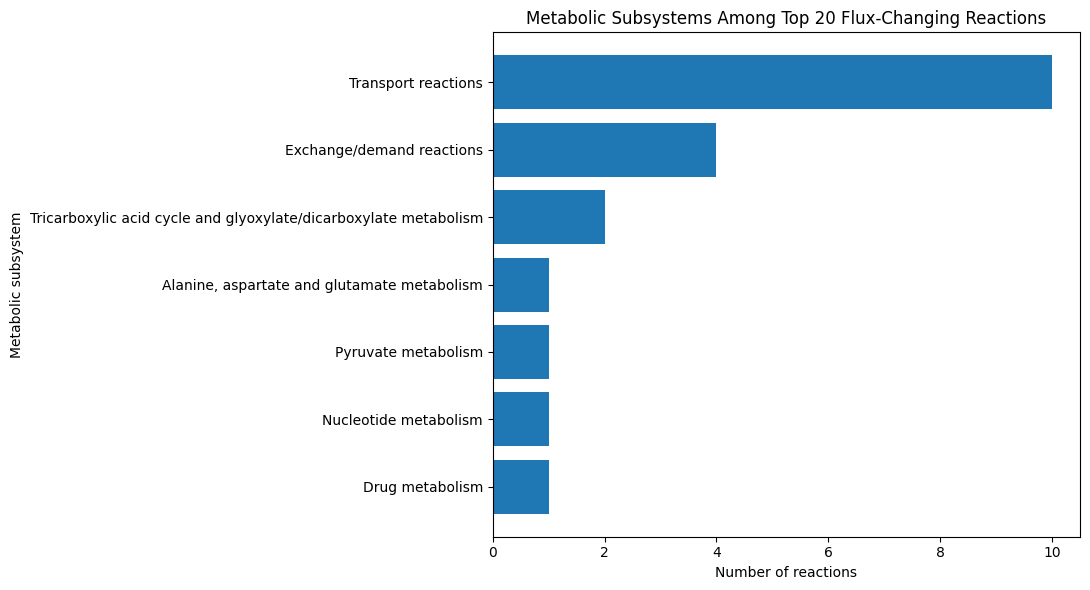

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.barh(
    subsystem_summary["Metabolic_Subsystem"],
    subsystem_summary["Number_of_Reactions"]
)

plt.xlabel("Number of reactions")
plt.ylabel("Metabolic subsystem")
plt.title("Metabolic Subsystems Among Top 20 Flux-Changing Reactions")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "/content/iMAT_subsystem_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [58]:
# Exclude transport and exchange/demand reactions
internal_reactions = top_reaction_analysis[
    ~top_reaction_analysis["Subsystem"].isin([
        "Transport reactions",
        "Exchange/demand reactions"
    ])
].copy()

# Display internal metabolic reactions
print("INTERNAL METABOLIC REACTIONS")
print("----------------------------")

display(
    internal_reactions[
        [
            "Reaction_ID",
            "Reaction_Name",
            "Subsystem",
            "Net_Flux_15",
            "Net_Flux_10",
            "Absolute_Difference",
            "Gene_Rule"
        ]
    ]
)

INTERNAL METABOLIC REACTIONS
----------------------------


,Reaction_ID,Reaction_Name,Subsystem,Net_Flux_15,Net_Flux_10,Absolute_Difference,Gene_Rule
2,MAR06970,,"Alanine, aspartate and glutamate metabolism",-1000.000000,999.980000,1999.980000,ENSG00000167701
7,MAR04280,(S)-Lactate:NAD+ oxidoreductase,Pyruvate metabolism,999.980000,-728.001277,1727.981277,ENSG00000111716 or ENSG00000171989
9,MAR04410,(S)-malate hydro-lyase (fumarate-forming),Tricarboxylic acid cycle and glyoxylate/dicarb...,1000.000000,-608.419668,1608.419668,ENSG00000091483
10,MAR08477,ATP:deoxycitidine 5'-phosphotransferase,Nucleotide metabolism,-626.979503,961.734552,1588.714056,ENSG00000156136
13,MAR04139,(S)-malate:NAD+ oxidoreductase,Tricarboxylic acid cycle and glyoxylate/dicarb...,1000.000000,-504.277756,1504.277756,ENSG00000014641 or ENSG00000138400
14,MAR13002,H2O2itr,Drug metabolism,423.284862,-1000.000000,1423.284862,


In [59]:
internal_reactions.to_csv(
    "/content/top_internal_metabolic_reactions.csv",
    index=False
)

print("Internal metabolic reaction analysis saved!")

Internal metabolic reaction analysis saved!


In [60]:
# Exclude transport and exchange/demand reactions
internal_reactions = top_reaction_analysis[
    ~top_reaction_analysis["Subsystem"].isin([
        "Transport reactions",
        "Exchange/demand reactions"
    ])
].copy()

# Display important columns
print("INTERNAL METABOLIC REACTIONS")
print("----------------------------")

display(
    internal_reactions[
        [
            "Reaction_ID",
            "Reaction_Name",
            "Subsystem",
            "Net_Flux_15",
            "Net_Flux_10",
            "Absolute_Difference",
            "Gene_Rule"
        ]
    ]
)

INTERNAL METABOLIC REACTIONS
----------------------------


,Reaction_ID,Reaction_Name,Subsystem,Net_Flux_15,Net_Flux_10,Absolute_Difference,Gene_Rule
2,MAR06970,,"Alanine, aspartate and glutamate metabolism",-1000.000000,999.980000,1999.980000,ENSG00000167701
7,MAR04280,(S)-Lactate:NAD+ oxidoreductase,Pyruvate metabolism,999.980000,-728.001277,1727.981277,ENSG00000111716 or ENSG00000171989
9,MAR04410,(S)-malate hydro-lyase (fumarate-forming),Tricarboxylic acid cycle and glyoxylate/dicarb...,1000.000000,-608.419668,1608.419668,ENSG00000091483
10,MAR08477,ATP:deoxycitidine 5'-phosphotransferase,Nucleotide metabolism,-626.979503,961.734552,1588.714056,ENSG00000156136
13,MAR04139,(S)-malate:NAD+ oxidoreductase,Tricarboxylic acid cycle and glyoxylate/dicarb...,1000.000000,-504.277756,1504.277756,ENSG00000014641 or ENSG00000138400
14,MAR13002,H2O2itr,Drug metabolism,423.284862,-1000.000000,1423.284862,


In [61]:
internal_reactions.to_csv(
    "/content/top_internal_metabolic_reactions.csv",
    index=False
)

print("Internal metabolic reaction analysis saved!")

Internal metabolic reaction analysis saved!


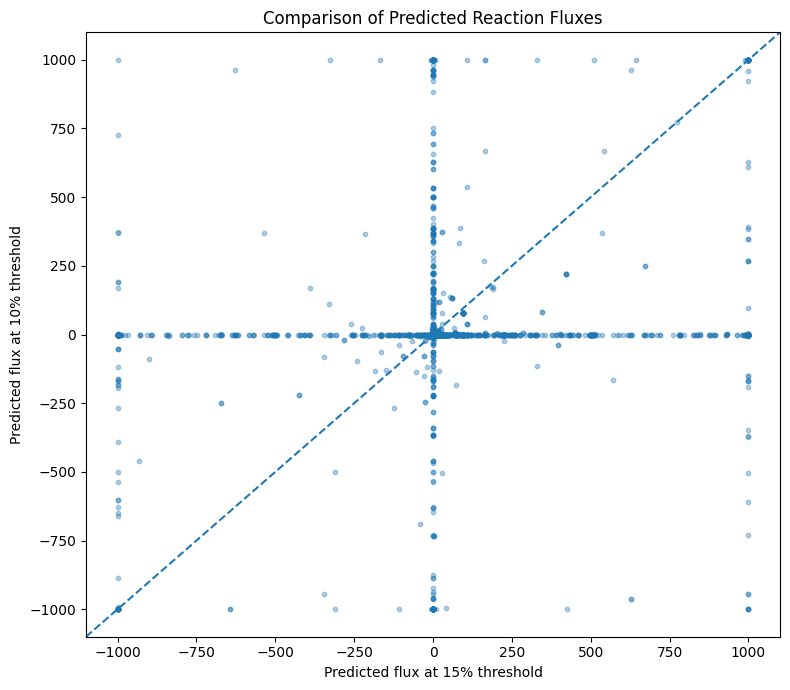

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.scatter(
    flux_comparison["Net_Flux_15"],
    flux_comparison["Net_Flux_10"],
    alpha=0.35,
    s=10
)

plt.xlabel("Predicted flux at 15% threshold")
plt.ylabel("Predicted flux at 10% threshold")
plt.title("Comparison of Predicted Reaction Fluxes")

plt.axline((0, 0), slope=1, linestyle="--")

plt.tight_layout()
plt.savefig(
    "/content/iMAT_flux_scatter.png",
    dpi=300
)
plt.show()

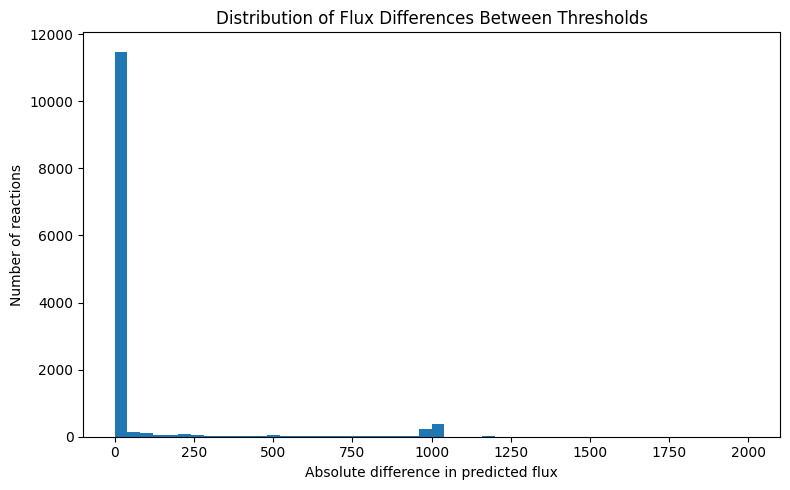

In [63]:
plt.figure(figsize=(8, 5))

plt.hist(
    flux_comparison["Absolute_Difference"],
    bins=50
)

plt.xlabel("Absolute difference in predicted flux")
plt.ylabel("Number of reactions")
plt.title("Distribution of Flux Differences Between Thresholds")

plt.tight_layout()
plt.savefig(
    "/content/iMAT_flux_difference_distribution.png",
    dpi=300
)
plt.show()

In [64]:
flux_comparison.to_csv(
    "/content/iMAT_flux_comparison_10_vs_15.csv",
    index=False
)

print("Final flux comparison data saved!")

Final flux comparison data saved!


In [65]:
from google.colab import files

files.download("/content/iMAT_flux_scatter.png")
files.download("/content/iMAT_flux_difference_distribution.png")
files.download("/content/iMAT_subsystem_distribution.png")
files.download("/content/iMAT_flux_comparison_10_vs_15.csv")
files.download("/content/iMAT_sensitivity_comparison.csv")
files.download("/content/top_20_changing_reactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>